In [1]:
import torch.nn as nn
import torchvision
import torch
from torchinfo import summary
from DWT import DWT_2D
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
import ast
from scipy import stats
from tqdm import tqdm
import time

import os
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import roc_auc_score, confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.metrics import roc_curve, auc, accuracy_score, confusion_matrix, f1_score
import seaborn as sns

from IXCM import IXCNet
from Loss import bce_loss, var_loss

In [2]:
'''
LABEL_COLUMNS = [
    'Atelectasis', 'Consolidation', 'Edema', 'Cardiomegaly', 'Lung Lesion', 'Lung Opacity',
    'Pleural Effusion', 'Pneumonia', 'Pneumothorax'
]
'''
LABEL_COLUMNS = [
    'Consolidation', 'Edema', 'Cardiomegaly', 'Pleural Effusion', 'Pneumonia'
]

class MIMICXrayDataset(Dataset):
    """
    逻辑：
    1. 直接解析 image_paths_list 中的路径字符串。
    2. 优先选择路径中包含 'PA' 的图片。
    3. 如果没有，退而求其次选择包含 'AP' 的图片。
    4. 都没有，默认取第一张。
    5. 返回单通道灰度图张量 (1, H, W)。
    """

    def __init__(self, dataframe, transform=None, class_name=['Atelectasis']):
        self.dataframe = dataframe
        self.transform = transform
        # 确保 LABEL_COLUMNS 已定义
        self.labels = torch.tensor(self.dataframe[class_name].values, dtype=torch.float32)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # 1. 获取路径列表
        image_paths_list = self.dataframe.iloc[idx]['image_paths_list']
        labels = self.labels[idx]

        selected_path = None

        # 2. 筛选逻辑：基于路径字符串匹配
        # 假设路径类似于: '/local_mimic/Images/PA/58224503_PA_1.jpeg'
        
        # 策略 A: 寻找 PA (优先)
        # 检查路径中是否有 'PA' (为了更严谨，可以检查 '/PA/' 或 '_PA_')
        pa_paths = [p for p in image_paths_list if 'PA' in p]
        
        if len(pa_paths) > 0:
            # 找到 PA，取第一张
            selected_path = pa_paths[0]
        else:
            # 策略 B: 没有 PA，寻找 AP
            ap_paths = [p for p in image_paths_list if 'AP' in p]
            if len(ap_paths) > 0:
                selected_path = ap_paths[0]
            else:
                # 策略 C: 兜底 (既无 PA 也无 AP 标识)，取列表第一张
                selected_path = image_paths_list[0]

        # 3. 加载图像 & 强制转单通道
        # .convert('L') 是核心，确保无论原图是否被存为 RGB，读进来都是单通道

        image = Image.open(selected_path).convert('L')

        # 4. 预处理
        if self.transform:
            image = self.transform(image)

        return image, labels

In [3]:
def train_one_epoch(model, dataloader, criterion_bce, criterion_var, optimizer, device, gc=0.01, loss_mode='bcevar', var_weight=1.0, img_dec=True):
    model.train()
    
    # 累加器
    run_loss = 0.0
    run_bce = 0.0
    run_var = 0.0
    
    preds_list = []
    labels_list = []

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward
        alphas, betas, outs = model(inputs)

        # Loss 计算
        loss_bce = criterion_bce(outs, labels)

        # 解析 alpha/beta (ydim=1)
        # alpha_s = alphas[:, 0:1]
        # alpha_a = alphas[:, 1:2]
        # beta_s  = betas[:, 0:1]
        # beta_a  = betas[:, 1:2]
            
        if loss_mode == 'bcevar':
            if img_dec:
                alpha_s = alphas[:, 0::2]  
                beta_s  = betas[:, 0::2]
                alpha_a = alphas[:, 1::2]
                beta_a  = betas[:, 1::2]
                loss_var = criterion_var(alpha_s, beta_s, alpha_a, beta_a, labels)
            else:
                alpha_s = alphas
                beta_s  = betas
                loss_var = criterion_var(alpha_s, beta_s, alpha_s, beta_s, labels)
            loss = loss_bce + var_weight * loss_var
        else:
            loss = loss_bce

        loss.backward()
        # 1. 计算当前的梯度总范数 (在裁剪前)
        #total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1e6) # 这里设个无穷大只是为了算值，不裁剪
        
        # [调试打印] 看看平时是多少，爆炸时是多少
        # 建议只在每个 epoch 的前几个 batch 打印，防止刷屏
        #print(f"Gradient Norm: {total_norm:.4f}")
        # 梯度裁剪，防止BCE损失和VAR损失对抗带来的梯度陡增
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=gc)
        optimizer.step()

        # 记录数值 (batch_size 加权)
        bs = inputs.size(0)
        run_loss += loss.item() * bs
        run_bce  += loss_bce.item() * bs
        if loss_mode == 'bcevar':
            run_var  += loss_var.item() * bs
            
        
        # 收集预测结果用于计算指标
        preds_list.extend(outs.detach().cpu().numpy())
        labels_list.extend(labels.cpu().numpy())

    # 计算 Epoch 平均值
    dataset_size = len(dataloader.dataset)
    epoch_loss = run_loss / dataset_size
    epoch_bce  = run_bce / dataset_size
    epoch_var  = run_var / dataset_size
    
    # 计算指标
    preds_arr = np.array(preds_list)
    labels_arr = np.array(labels_list)
    preds_bin = preds_arr > 0.5
    
    # acc = accuracy_score(labels_arr, preds_bin)
    correct_prediction = (preds_bin == labels_arr)
    class_accs = np.mean(correct_prediction, axis=0)
    acc = np.mean(class_accs)
    # 防止只有一个类别导致AUC报错
    try:
        auc = roc_auc_score(labels_arr, preds_arr, average='macro')
    except ValueError:
        auc = 0.5 

    return epoch_loss, epoch_bce, epoch_var, acc, auc

def validate(model, dataloader, criterion_bce, criterion_var, device, loss_mode='bcevar', var_weight=1.0, img_dec=True):
    model.eval()
    
    # 累加器
    run_loss = 0.0
    run_bce = 0.0
    run_var = 0.0
    
    preds_list = []
    labels_list = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            alphas, betas, outs = model(inputs)

            loss_bce = criterion_bce(outs, labels)
            
            if loss_mode=='bcevar':
                if img_dec:
                    alpha_s = alphas[:, 0::2]  
                    beta_s  = betas[:, 0::2]
                    alpha_a = alphas[:, 1::2]
                    beta_a  = betas[:, 1::2]
                    loss_var = criterion_var(alpha_s, beta_s, alpha_a, beta_a, labels)
                else:
                    alpha_s = alphas
                    beta_s  = betas
                    loss_var = criterion_var(alpha_s, beta_s, alpha_s, beta_s, labels)
                loss = loss_bce + var_weight * loss_var
            else:
                loss = loss_bce

            bs = inputs.size(0)
            run_loss += loss.item() * bs
            run_bce  += loss_bce.item() * bs
            if loss_mode == 'bcevar':
                run_var  += loss_var.item() * bs

            preds_list.extend(outs.cpu().numpy())
            labels_list.extend(labels.cpu().numpy())

    dataset_size = len(dataloader.dataset)
    epoch_loss = run_loss / dataset_size
    epoch_bce  = run_bce / dataset_size
    epoch_var  = run_var / dataset_size
    
    preds_arr = np.array(preds_list)
    labels_arr = np.array(labels_list)
    preds_bin = preds_arr > 0.5
    
    # acc = accuracy_score(labels_arr, preds_bin)
    correct_prediction = (preds_bin == labels_arr)
    class_accs = np.mean(correct_prediction, axis=0)
    acc = np.mean(class_accs)
    try:
        auc = roc_auc_score(labels_arr, preds_arr, average='macro')
    except ValueError:
        auc = 0.5

    return epoch_loss, epoch_bce, epoch_var, acc, auc, labels_arr, preds_bin

In [4]:
class EarlyStopping:
    """
    当验证集损失在 patience 个 epoch 内没有改善时停止训练。
    """
    def __init__(self, patience=7, verbose=False, delta=0, path='checkpoint.pth', trace_func=print):
        """
        Args:
            patience (int): 上次验证集损失改善后等待的 epoch 数。
            verbose (bool): 如果为 True，则打印每一步的日志。
            delta (float): 只有变化量超过 delta 才被认为是改善。
            path (str): 保存最佳模型权重的路径。
            trace_func (function): 用于打印日志的函数。
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta
        self.path = path
        self.trace_func = trace_func

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                self.trace_func(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        '''验证集损失减少时保存模型'''
        if self.verbose:
            self.trace_func(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}).  Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

# ==========================================
# 2. 高级训练策略函数
# ==========================================
def train_model_with_strategy(
    model, 
    train_loader, 
    val_loader, 
    criterion_bce, 
    criterion_var, 
    device,
    epochs=50,
    lr_start=1e-3, 
    lr_end=1e-6,
    warmup_epochs=5,  # 预热轮数
    use_early_stopping=True,
    patience=10,
    use_scheduler=True,
    weight_decay=0.01,
    gradient_clip=3.0,
    loss_mode='bcevar',
    var_weight=1.0,
    save_dir='./checkpoints',
    img_dec=True
):
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    best_acc = 0.0
    best_auc = 0.0
    best_loss = 1e8
    best_bce = 1e8
    best_var = 1e8
    # 1. 定义优化器 (初始设为 lr_start, 但前几个epoch会被覆盖)
    optimizer = optim.Adam(model.parameters(), lr=lr_start, weight_decay=weight_decay)
    
    # 2. 定义调度器
    # 注意: T_max 应该是剩余的 "正式训练" 轮数
    scheduler = None
    if use_scheduler:
        scheduler_epochs = epochs - warmup_epochs
        if scheduler_epochs > 0:
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=scheduler_epochs, eta_min=lr_end)
    
    early_stopping = EarlyStopping(patience=patience, verbose=False, path='best_model_strategy.pth')

    history = {
        'train': {'loss': [], 'bce': [], 'var': [], 'acc': [], 'auc': []},
        'val':   {'loss': [], 'bce': [], 'var': [], 'acc': [], 'auc': []},
        'lr': []
    }

    print(f"{'='*100}")
    print(f"Start Training: Total Epochs={epochs}")
    if use_scheduler:
        print(f"Strategy: Warmup ({warmup_epochs} epochs @ {lr_end:.1e}) -> CosineAnnealing ({lr_start:.1e}->{lr_end:.1e})")
    else:
        print(f"Strategy: Constant Learning Rate ({lr_start:.1e})")
    print(f"{'='*100}")
    for epoch in range(epochs):
        epoch_start_time = time.time()
        if use_scheduler:
            # --- 分支 A: 开启调度 (预热 + 退火) ---
            if epoch < warmup_epochs:
                # 预热阶段：强制使用最小学习率
                current_lr = lr_end
                for param_group in optimizer.param_groups:
                    param_group['lr'] = current_lr
                phase_name = "Warmup"
            else:
                # 正式阶段：
                # 如果是预热结束后的第一个epoch，先确保LR重置回lr_start，让Scheduler接管
                if epoch == warmup_epochs:
                    for param_group in optimizer.param_groups:
                        param_group['lr'] = lr_start
                
                current_lr = optimizer.param_groups[0]['lr']
                phase_name = "Anneal"
        else:
            # --- 分支 B: 关闭调度 (恒定学习率) ---
            # 保持优化器初始化时的 lr_start 不变
            # 也可以在这里强制赋值以防万一，但通常不需要
            current_lr = optimizer.param_groups[0]['lr'] 
            phase_name = "Constant"

        # --- 训练 ---
        t_loss, t_bce, t_var, t_acc, t_auc = train_one_epoch(
            model, train_loader, criterion_bce, criterion_var, optimizer, device, gc=gradient_clip, loss_mode=loss_mode, var_weight=var_weight, img_dec=img_dec
        )
        
        # --- 验证 ---
        v_loss, v_bce, v_var, v_acc, v_auc, _, _ = validate(
            model, val_loader, criterion_bce, criterion_var, device, loss_mode=loss_mode, var_weight=var_weight, img_dec=img_dec
        )
        
        # --- 调度器更新逻辑 ---
        if use_scheduler and scheduler is not None and epoch >= warmup_epochs:
            scheduler.step()
            
        epoch_end_time = time.time()
        epoch_duration = epoch_end_time - epoch_start_time
        epoch_mins = int(epoch_duration // 60)
        epoch_secs = int(epoch_duration % 60)

        # --- 记录 ---
        history['train']['loss'].append(t_loss)
        history['train']['bce'].append(t_bce)
        history['train']['var'].append(t_var)
        history['train']['acc'].append(t_acc)
        history['train']['auc'].append(t_auc)
        
        history['val']['loss'].append(v_loss)
        history['val']['bce'].append(v_bce)
        history['val']['var'].append(v_var)
        history['val']['acc'].append(v_acc)
        history['val']['auc'].append(v_auc)
        history['lr'].append(current_lr)

        # --- 格式化打印 (增加阶段标识) ---
        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] [{phase_name}] LR: {current_lr:.2e} Time: {epoch_mins}m {epoch_secs}s")
        print(f"  Train | Loss: {t_loss:.4f} (BCE: {t_bce:.4f}, Var: {t_var:.4f}) | Acc: {t_acc:.4f} | AUC: {t_auc:.4f}")
        print(f"  Val   | Loss: {v_loss:.4f} (BCE: {v_bce:.4f}, Var: {v_var:.4f}) | Acc: {v_acc:.4f} | AUC: {v_auc:.4f}")

        if v_loss < best_loss:
            best_loss = v_loss
            save_path_loss = os.path.join(save_dir, 'best_model_loss.pth')
            torch.save(model.state_dict(), save_path_loss)
            print(f"  -> [Saved] Best Loss updated: {best_loss:.4f}")

        if v_bce < best_bce:
            best_bce = v_bce
            save_path_bce = os.path.join(save_dir, 'best_model_bce.pth')
            torch.save(model.state_dict(), save_path_bce)
            print(f"  -> [Saved] Best BCE updated: {best_bce:.4f}")

        if v_var < best_var:
            best_var = v_var
            save_path_var = os.path.join(save_dir, 'best_model_var.pth')
            torch.save(model.state_dict(), save_path_var)
            print(f"  -> [Saved] Best VAR updated: {best_var:.4f}")
            
        if v_acc > best_acc:
            best_acc = v_acc
            save_path_acc = os.path.join(save_dir, 'best_model_acc.pth')
            torch.save(model.state_dict(), save_path_acc)
            print(f"  -> [Saved] Best Acc updated: {best_acc:.4f}")
        
        # 2. 保存最佳 AUC 模型
        if v_auc > best_auc:
            best_auc = v_auc
            save_path_auc = os.path.join(save_dir, 'best_model_auc.pth')
            torch.save(model.state_dict(), save_path_auc)
            print(f"  -> [Saved] Best AUC updated: {best_auc:.4f}")
            
        print("-" * 100)

        # --- 早停 ---
        if use_early_stopping:
            early_stopping(v_loss, model)
            if early_stopping.early_stop:
                print(f"Early stopping triggered at epoch {epoch+1}!")
                break
    
    if use_early_stopping:
        print("Loading best model weights...")
        model.load_state_dict(torch.load('best_model_strategy.pth'))

    return model, history

In [5]:
def plot_loss_curve(train_losses, val_losses, save_path='./loss_curve.png', metric_name='Loss') :
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label=f'Train {metric_name}')
    plt.plot(val_losses, label=f'Val {metric_name}')
    plt.title(f'Training and Validation {metric_name}')
    plt.xlabel('Epochs')
    if metric_name == "AUC" or metric_name == "ACC":
        plt.ylim([0, 1.1])
    plt.ylabel(f'{metric_name}')
    plt.legend()
    plt.grid(True)
    plt.savefig(save_path)
    # plt.show()

In [6]:
def seed_everything(seed=42):
    """
    固定所有随机种子以保证实验可复现性
    """
    # 1. Python标准库
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 2. NumPy
    np.random.seed(seed)
    
    # 3. PyTorch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # 如果使用多卡
    
    # 4. CuDNN (最关键的一步)
    # 保证卷积算法选择的确切性
    torch.backends.cudnn.deterministic = True 
    # 禁止寻找最优卷积算法（虽然会稍微降低速度，但能保证完全一致）
    torch.backends.cudnn.benchmark = False

    print(f"Random Seed set to: {seed}")

Random Seed set to: 42
Train samples: 18429, Val samples: 131, Test samples: 295
✅ Building IXCNet with backbone: densenet121


/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start Training: Total Epochs=80
Strategy: Warmup (0 epochs @ 1.0e-04) -> CosineAnnealing (5.0e-04->1.0e-04)
Epoch [01/80] [Anneal] LR: 5.00e-04 Time: 2m 24s
  Train | Loss: 2.0474 (BCE: 0.5924, Var: 1.4550) | Acc: 0.6878 | AUC: 0.7481
  Val   | Loss: 2.2285 (BCE: 0.5675, Var: 1.6610) | Acc: 0.7405 | AUC: 0.8305
  -> [Saved] Best Loss updated: 2.2285
  -> [Saved] Best BCE updated: 0.5675
  -> [Saved] Best VAR updated: 1.6610
  -> [Saved] Best Acc updated: 0.7405
  -> [Saved] Best AUC updated: 0.8305
----------------------------------------------------------------------------------------------------
Epoch [02/80] [Anneal] LR: 5.00e-04 Time: 2m 20s
  Train | Loss: 1.8478 (BCE: 0.5346, Var: 1.3132) | Acc: 0.7373 | AUC: 0.8054
  Val   | Loss: 1.8519 (BCE: 0.5440, Var: 1.3079) | Acc: 0.7099 | AUC: 0.8701
  -> [Saved] Best Loss updated: 1.8519
  -> [Saved] Best BCE updated: 0.5440
  -> [Saved] Best VAR updated: 1.3079
  -> [Saved] Best AUC updated: 0.8701
-------------------------------------

/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start Training: Total Epochs=80
Strategy: Warmup (0 epochs @ 1.0e-04) -> CosineAnnealing (5.0e-04->1.0e-04)
Epoch [01/80] [Anneal] LR: 5.00e-04 Time: 7m 58s
  Train | Loss: 1.7592 (BCE: 0.5013, Var: 1.2578) | Acc: 0.7623 | AUC: 0.8360
  Val   | Loss: 1.5703 (BCE: 0.4357, Var: 1.1347) | Acc: 0.7976 | AUC: 0.8944
  -> [Saved] Best Loss updated: 1.5703
  -> [Saved] Best BCE updated: 0.4357
  -> [Saved] Best VAR updated: 1.1347
  -> [Saved] Best Acc updated: 0.7976
  -> [Saved] Best AUC updated: 0.8944
----------------------------------------------------------------------------------------------------
Epoch [02/80] [Anneal] LR: 5.00e-04 Time: 9m 2s
  Train | Loss: 1.5867 (BCE: 0.4529, Var: 1.1338) | Acc: 0.7938 | AUC: 0.8697
  Val   | Loss: 1.4614 (BCE: 0.4131, Var: 1.0483) | Acc: 0.8122 | AUC: 0.9005
  -> [Saved] Best Loss updated: 1.4614
  -> [Saved] Best BCE updated: 0.4131
  -> [Saved] Best VAR updated: 1.0483
  -> [Saved] Best Acc updated: 0.8122
  -> [Saved] Best AUC updated: 0.9005


...

/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start Training: Total Epochs=80
Strategy: Warmup (0 epochs @ 1.0e-04) -> CosineAnnealing (5.0e-04->1.0e-04)
Epoch [01/80] [Anneal] LR: 5.00e-04 Time: 9m 26s
  Train | Loss: 1.7386 (BCE: 0.4993, Var: 1.2393) | Acc: 0.7574 | AUC: 0.8033
  Val   | Loss: 1.4986 (BCE: 0.4006, Var: 1.0980) | Acc: 0.8173 | AUC: 0.8823
  -> [Saved] Best Loss updated: 1.4986
  -> [Saved] Best BCE updated: 0.4006
  -> [Saved] Best VAR updated: 1.0980
  -> [Saved] Best Acc updated: 0.8173
  -> [Saved] Best AUC updated: 0.8823
----------------------------------------------------------------------------------------------------
Epoch [02/80] [Anneal] LR: 5.00e-04 Time: 8m 34s
  Train | Loss: 1.4681 (BCE: 0.4205, Var: 1.0477) | Acc: 0.8110 | AUC: 0.8691
  Val   | Loss: 1.3067 (BCE: 0.3399, Var: 0.9668) | Acc: 0.8688 | AUC: 0.9218
  -> [Saved] Best Loss updated: 1.3067
  -> [Saved] Best BCE updated: 0.3399
  -> [Saved] Best VAR updated: 0.9668
  -> [Saved] Best Acc updated: 0.8688
  -> [Saved] Best AUC updated: 0.9218

/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start Training: Total Epochs=80
Strategy: Warmup (0 epochs @ 1.0e-04) -> CosineAnnealing (5.0e-04->1.0e-04)
Epoch [01/80] [Anneal] LR: 5.00e-04 Time: 4m 39s
  Train | Loss: 2.1406 (BCE: 0.6267, Var: 1.5139) | Acc: 0.6597 | AUC: 0.6692
  Val   | Loss: 2.0596 (BCE: 0.5921, Var: 1.4675) | Acc: 0.7176 | AUC: 0.7336
  -> [Saved] Best Loss updated: 2.0596
  -> [Saved] Best BCE updated: 0.5921
  -> [Saved] Best VAR updated: 1.4675
  -> [Saved] Best Acc updated: 0.7176
  -> [Saved] Best AUC updated: 0.7336
----------------------------------------------------------------------------------------------------
Epoch [02/80] [Anneal] LR: 5.00e-04 Time: 4m 12s
  Train | Loss: 2.0667 (BCE: 0.6051, Var: 1.4616) | Acc: 0.6871 | AUC: 0.7035
  Val   | Loss: 2.0089 (BCE: 0.5845, Var: 1.4244) | Acc: 0.6980 | AUC: 0.7385
  -> [Saved] Best Loss updated: 2.0089
  -> [Saved] Best BCE updated: 0.5845
  -> [Saved] Best VAR updated: 1.4244
  -> [Saved] Best AUC updated: 0.7385
-------------------------------------

/tmp/ipykernel_967/1936100357.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 5))


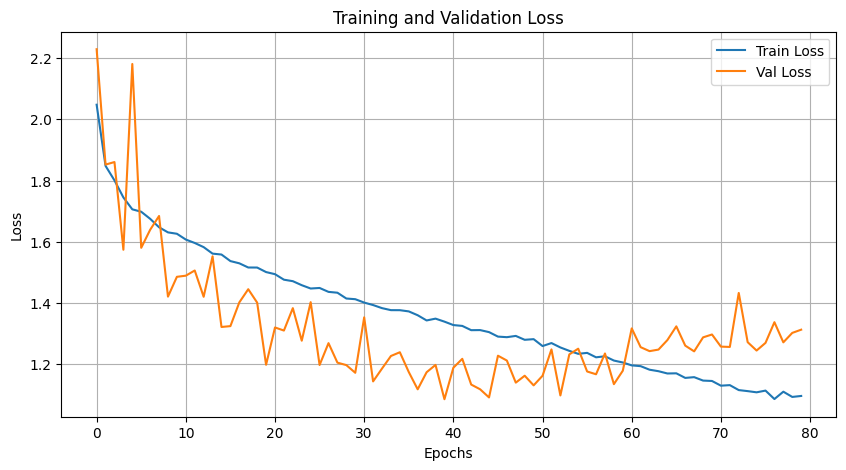

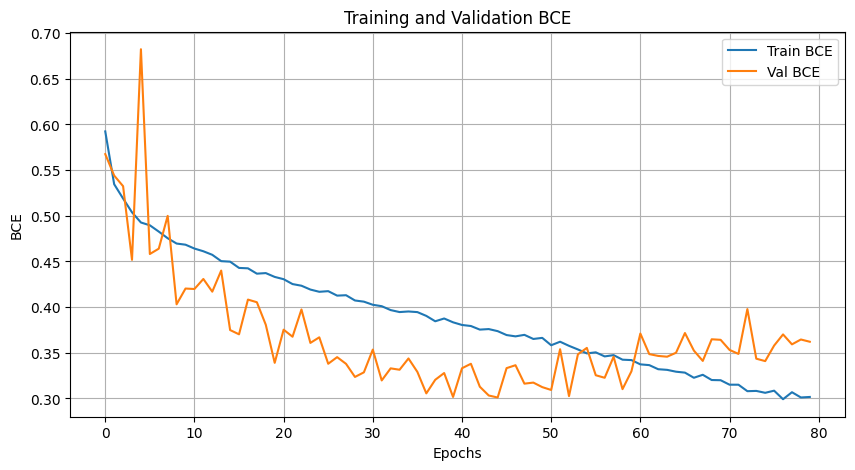

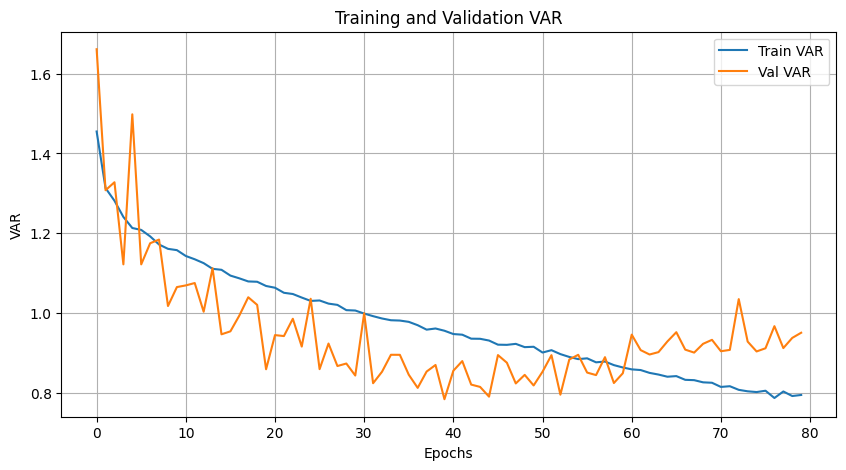

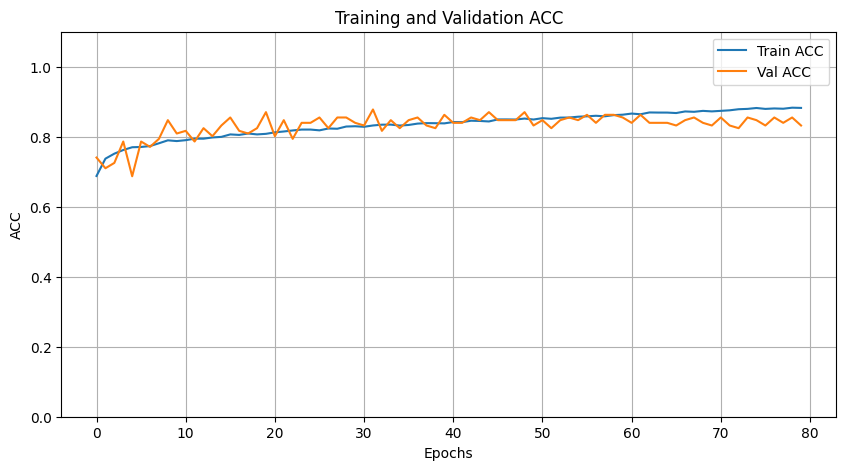

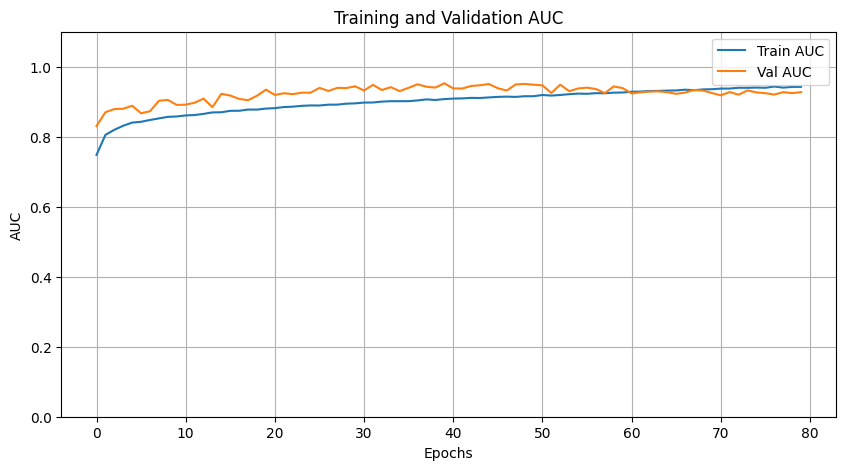

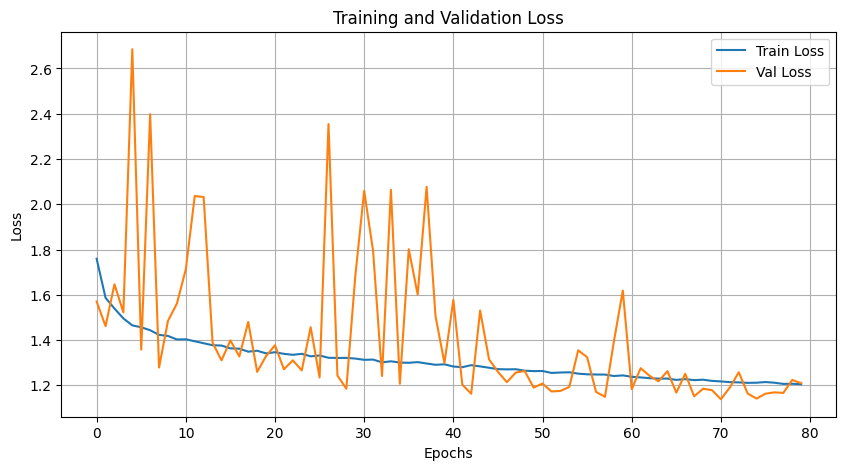

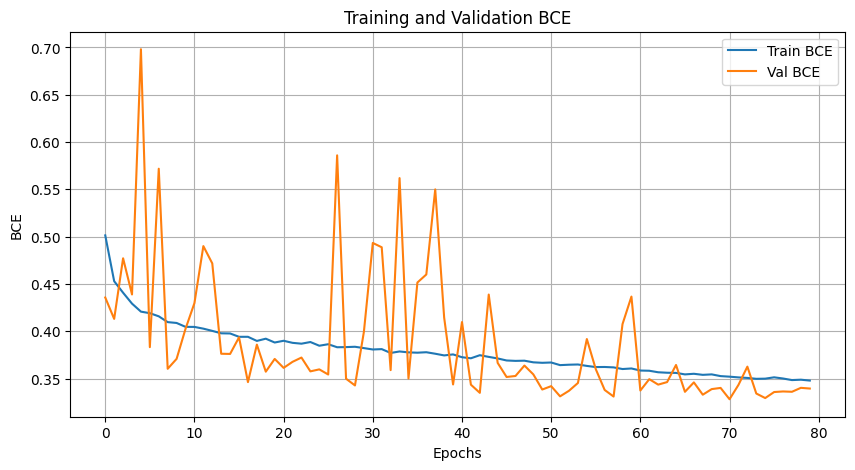

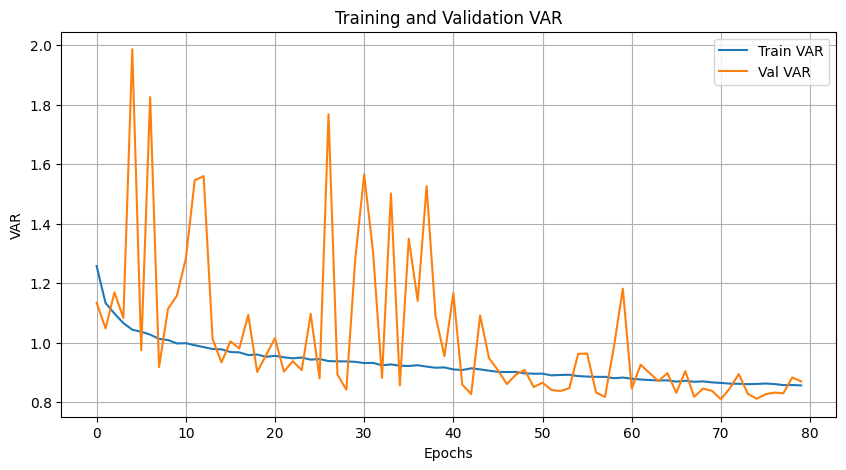

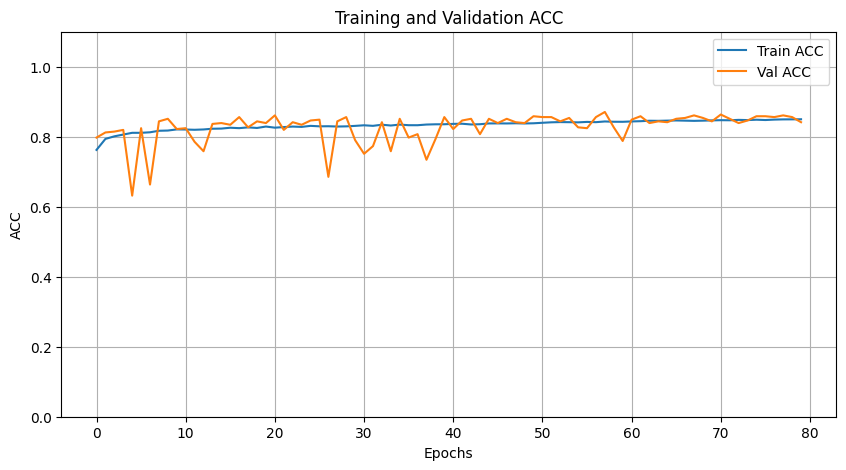

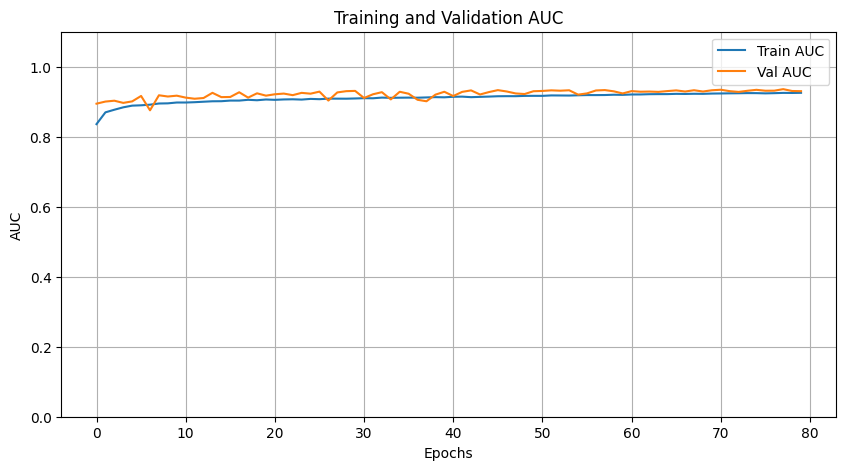

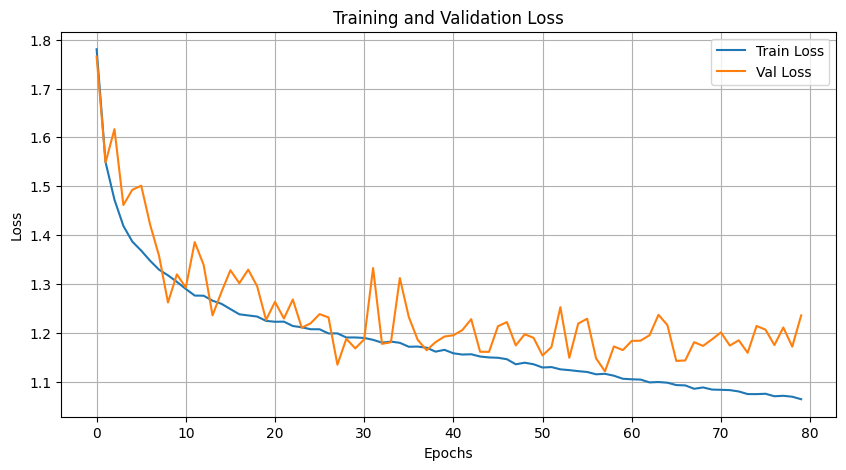

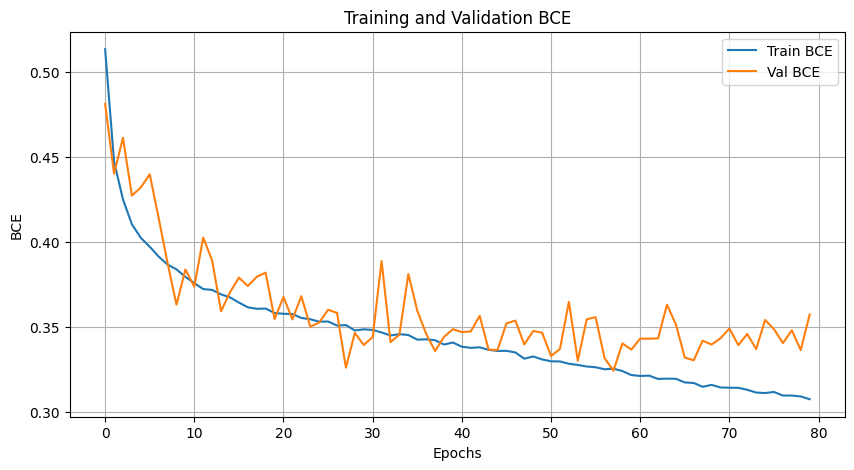

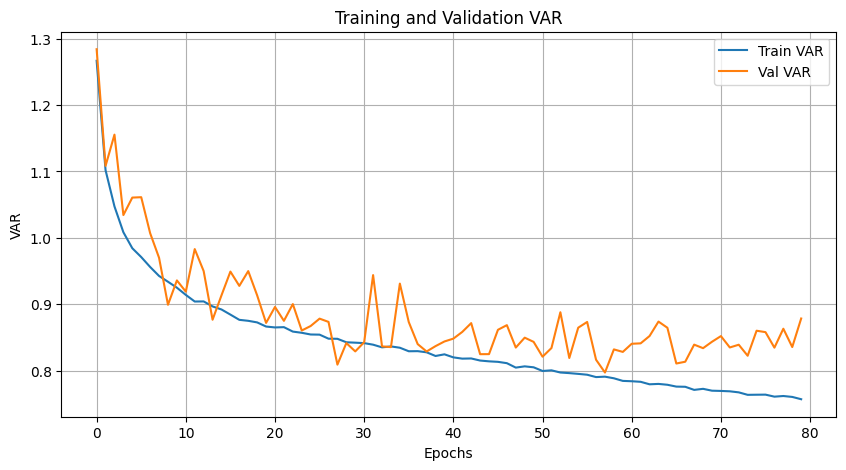

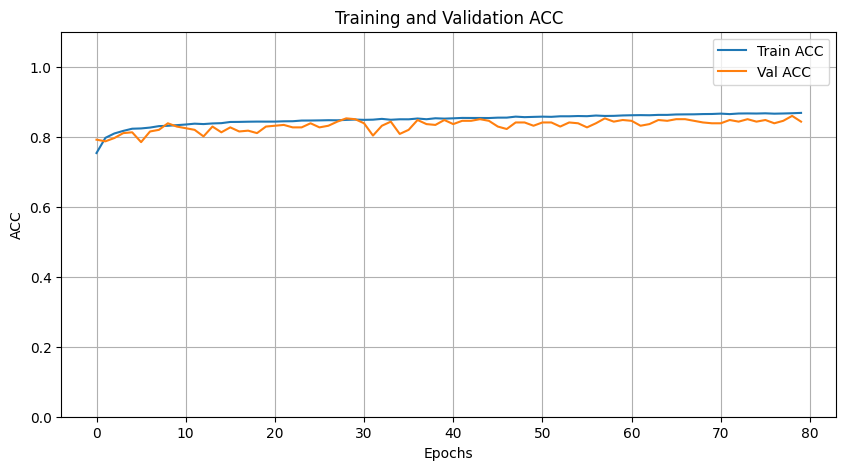

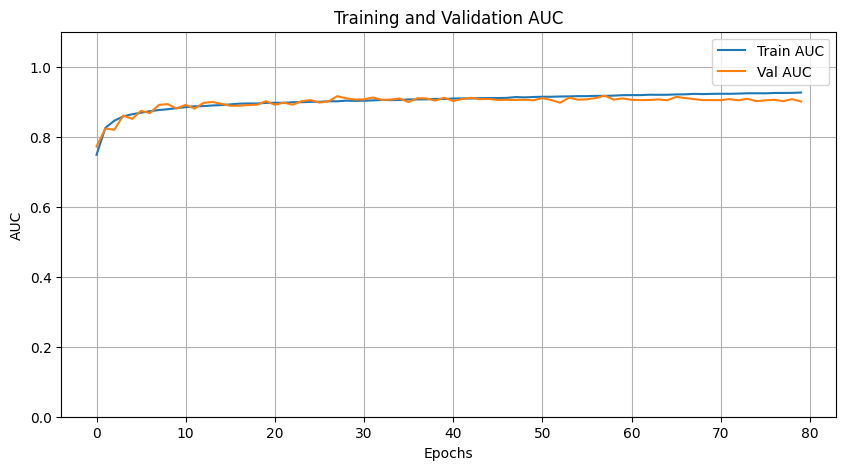

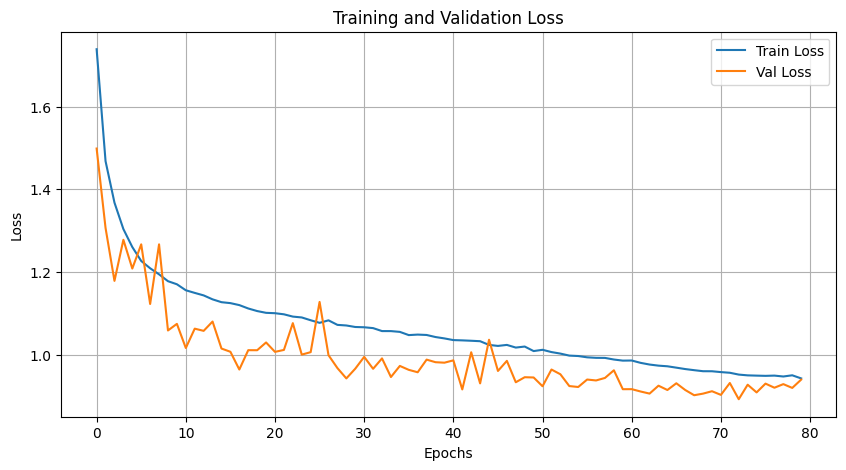

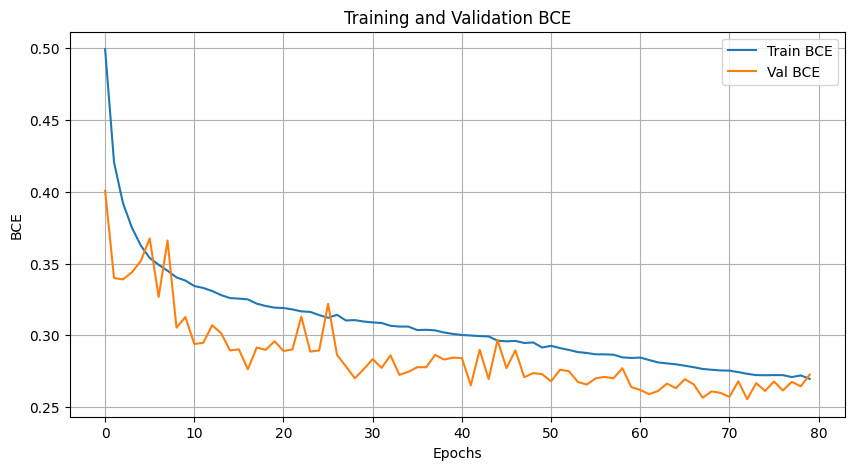

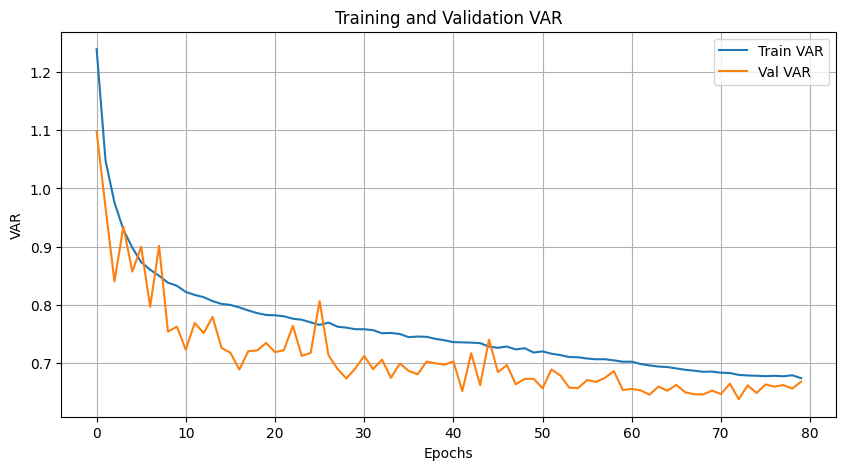

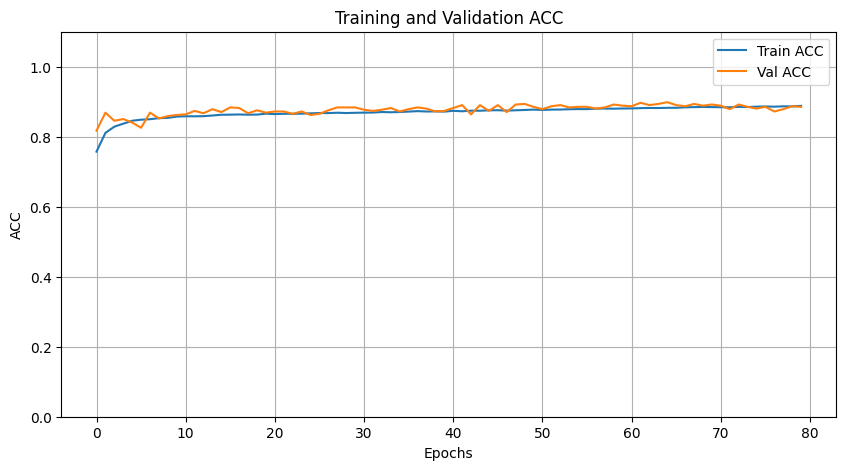

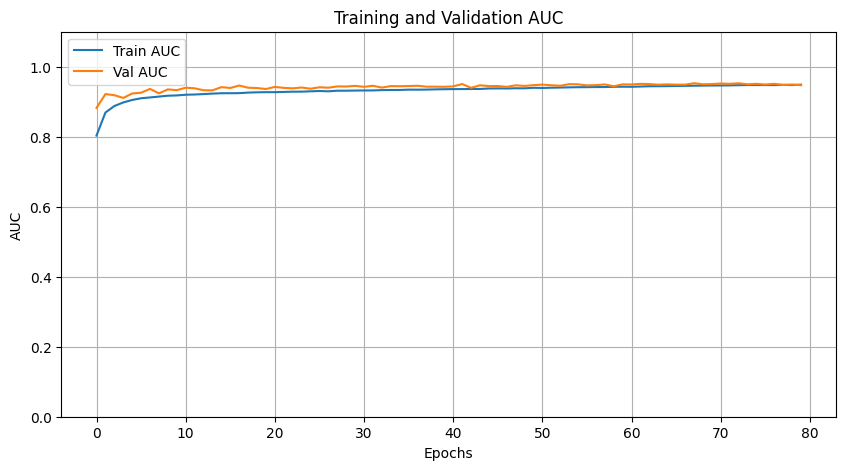

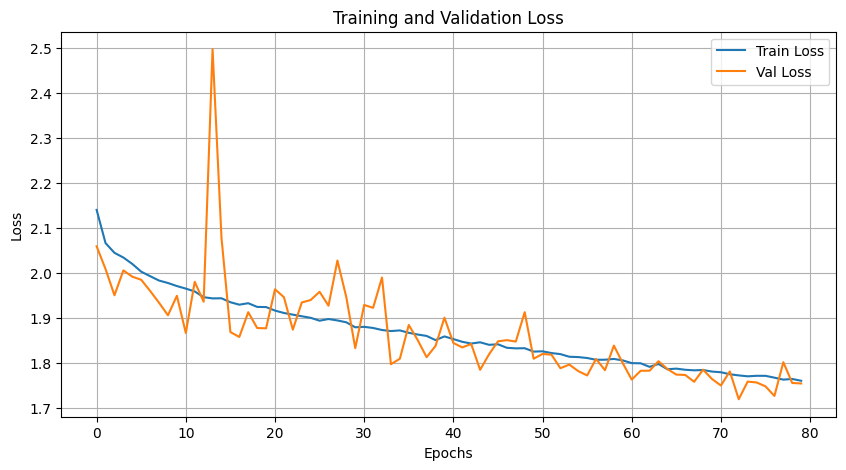

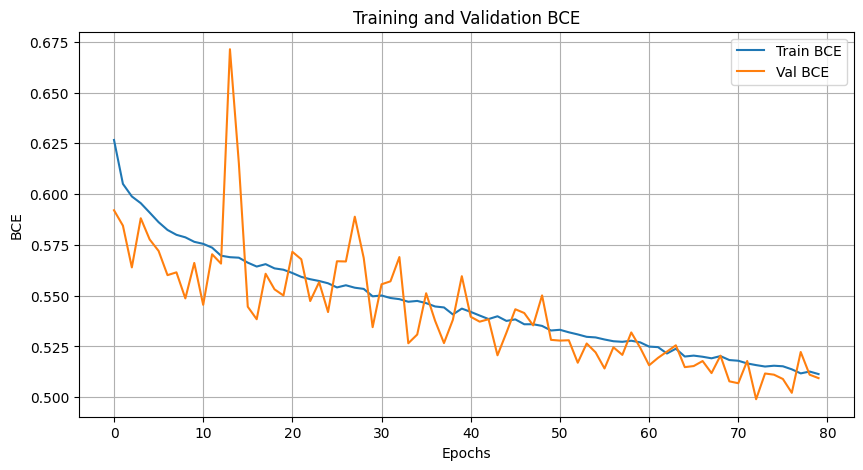

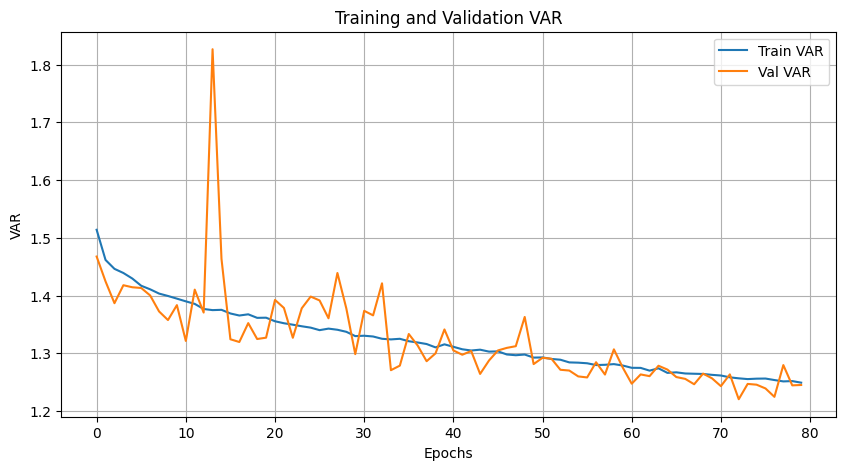

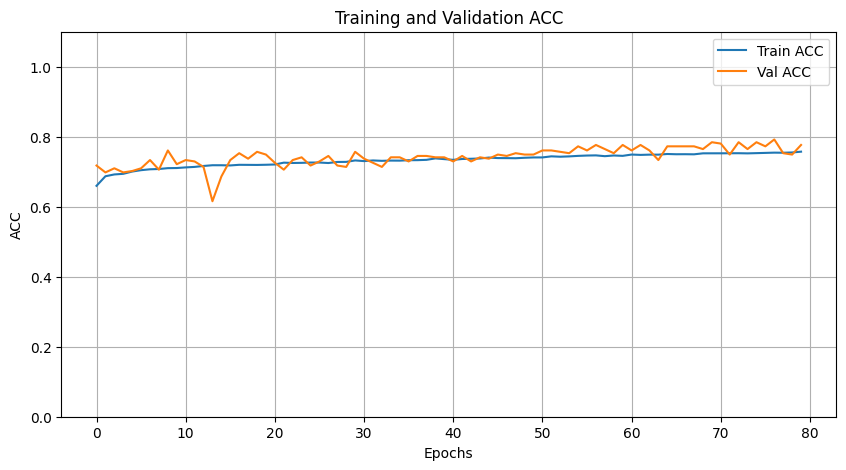

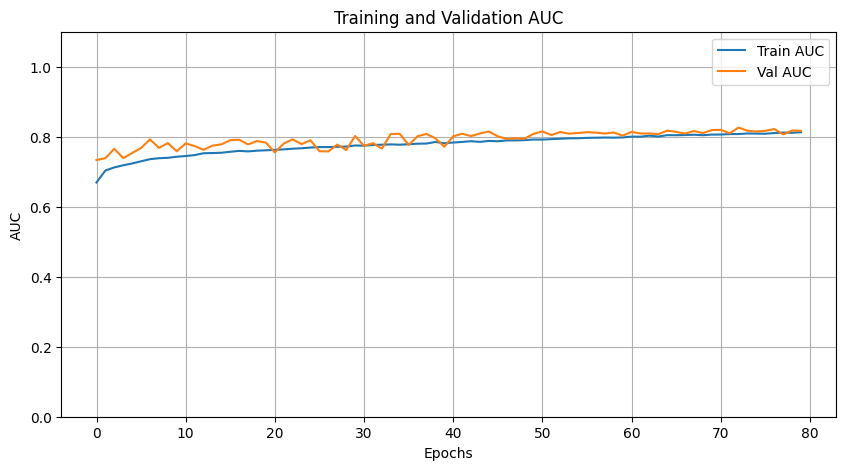

In [7]:
for LABEL_COLUMN in LABEL_COLUMNS:
    img_dec=True
    loss_mode = 'bcevar'
    class_name = [LABEL_COLUMN]
    seed_everything(42) # 固定随机种子保证结果可复现
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if img_dec:
        BATCH_SIZE = 64
    else:
        BATCH_SIZE = 32
    #存储study_id和对应图像路径列表的csv文件
    stid_imgpath_csv_path = f'./MIMIC_CSV/single_class_datasets/dataset_{class_name[0].replace(" ", "_")}.csv'
    stid_imgpath_df = pd.read_csv(stid_imgpath_csv_path)
    # 官方给出的split csv文件 方便横向对比
    train_val_test_split_csv_path = './MIMIC_CSV/mimic-cxr-2.0.0-split.csv'
    split_df = pd.read_csv(train_val_test_split_csv_path)
    
    train_study_ids = split_df[split_df['split'] == 'train']['study_id'].unique()
    val_study_ids = split_df[split_df['split'] == 'validate']['study_id'].unique()
    test_study_ids = split_df[split_df['split'] == 'test']['study_id'].unique()
    
    train_df = stid_imgpath_df[stid_imgpath_df['study_id'].isin(train_study_ids)].copy()
    val_df = stid_imgpath_df[stid_imgpath_df['study_id'].isin(val_study_ids)].copy()
    test_df = stid_imgpath_df[stid_imgpath_df['study_id'].isin(test_study_ids)].copy()
    
    def parse_and_fix_paths(path_str):
        # 步骤 A: 将字符串 "['/local/a.jpg', ...]" 解析为列表
        # 注意：如果数据已经是 list 类型了（防止重复运行报错），直接使用
        if isinstance(path_str, list):
            path_list = path_str
        else:
            path_list = ast.literal_eval(path_str)
        
        # 步骤 B: 列表推导式批量替换路径
        # 这里定义旧路径和新路径，方便修改
        OLD_ROOT = '/local_mimic'
        NEW_ROOT = '/course75/MIMIC-Xray'
        
        return [p.replace(OLD_ROOT, NEW_ROOT) for p in path_list]
    
    train_df['image_paths_list'] = train_df['image_paths_list'].apply(parse_and_fix_paths)
    val_df['image_paths_list'] = val_df['image_paths_list'].apply(parse_and_fix_paths)
    test_df['image_paths_list'] = test_df['image_paths_list'].apply(parse_and_fix_paths)
    
    train_transforms = transforms.Compose([
        transforms.Resize(540),
        transforms.RandomCrop(512),       # 或者 RandomResizedCrop
        transforms.RandomHorizontalFlip(), # 关键增强：水平翻转
        transforms.RandomRotation(10),     # 关键增强：正负10度旋转
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ])
    
    val_transforms = transforms.Compose([
        transforms.Resize(540),
        transforms.CenterCrop(512),       # 确定性裁剪
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ])
    
    train_dataset = MIMICXrayDataset(train_df, transform=train_transforms, class_name=class_name)
    val_dataset = MIMICXrayDataset(val_df, transform=val_transforms, class_name=class_name)
    test_dataset = MIMICXrayDataset(test_df, transform=val_transforms, class_name=class_name)
    
    print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")
    
    def worker_init_fn(worker_id):
        """
        为每个 DataLoader worker 设置独立的随机种子
        防止多进程加载数据时随机性重复或失效
        """
        # 获取当前的种子 (也就是你在 seed_everything 里设的 42)
        # 加上 worker_id 确保每个 worker 的种子不一样
        worker_seed = torch.initial_seed() % 2**32
        
        # 重新设置 numpy 和 random 的种子
        np.random.seed(worker_seed + worker_id)
        random.seed(worker_seed + worker_id)
        
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=8, pin_memory=True,
                              persistent_workers=True, prefetch_factor=2, worker_init_fn=worker_init_fn)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=8, pin_memory=True,
                            persistent_workers=True, prefetch_factor=2, worker_init_fn=worker_init_fn)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=8, pin_memory=True,
                             persistent_workers=True, prefetch_factor=2, worker_init_fn=worker_init_fn)

    # 配置你的高级参数
    result_root_path = f'./result/MIMIC/0208_{class_name[0].replace(" ", "_")}'
    weight_decay = 0.0001
    gradient_clip = 1.0
    var_weight = 1.0
    KL_lmd = 0.1
    # loss_mode = 'bce'
    lr=0.0005
    # img_dec=False
    result_root_path = result_root_path + '_wd' + str(weight_decay).replace('.', '_') + '_gc' + str(gradient_clip).replace('.', '_') + '_vw' + str(var_weight).replace('.', '_') + '_lm_' + loss_mode + '_lr_' + str(lr) + '_kllmd_' + str(KL_lmd) + '_imgdec_' + str(int(img_dec))
    STRATEGY_PARAMS = {
        'epochs': 80,           # 总 Epoch 设大一点，让早停去控制
        'lr_start': lr,       # 初始学习率 (刚开始大一点快速收敛)
        'lr_end': 1e-4,         # 结束学习率 (最后小一点精细微调)
        'use_early_stopping': False,
        'patience': 10,
        'warmup_epochs': 0,
        'use_scheduler': True,
        'weight_decay': weight_decay,
        'gradient_clip': gradient_clip,
        'loss_mode': loss_mode,
        'var_weight': var_weight,
        'save_dir': result_root_path,
        'img_dec': img_dec
    }

    # 重新实例化模型和损失函数（确保从头开始）
    model = IXCNet(evi_vec_dim=64, wavename='haar', ydim=1, in_channels=1, img_dec=img_dec).to(DEVICE)
    criterion_bce = bce_loss(reduction='mean')
    criterion_var = var_loss(reduction='mean', lmd=KL_lmd, img_dec=img_dec)
    
    # 调用策略训练函数
    final_model, history = train_model_with_strategy(
        model, 
        train_loader, 
        val_loader, 
        criterion_bce, 
        criterion_var, 
        DEVICE,
        **STRATEGY_PARAMS
    )
    
    history_path = os.path.join(result_root_path, 'history.npy')
    np.save(history_path, history)
    
    # 画 Loss 曲线
    plot_loss_curve(history['train']['loss'], history['val']['loss'], save_path=result_root_path + '/loss_history.png', metric_name="Loss")
    plot_loss_curve(history['train']['bce'], history['val']['bce'], save_path=result_root_path + '/bce_history.png', metric_name="BCE")
    plot_loss_curve(history['train']['var'], history['val']['var'], save_path=result_root_path + '/var_history.png', metric_name="VAR")
    plot_loss_curve(history['train']['acc'], history['val']['acc'], save_path=result_root_path + '/acc_history.png', metric_name="ACC")
    plot_loss_curve(history['train']['auc'], history['val']['auc'], save_path=result_root_path + '/auc_history.png', metric_name="AUC")